In [22]:
import matplotlib.pyplot as plt
import numpy as np

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Set a beautiful default style
sns.set_theme(
    style="whitegrid",
    context="notebook"
)


import missingno as msno
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')
import plotly.express as px
import plotly.io as pio
pio.renderers.default = 'iframe'
import plotly.subplots as sp
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import seaborn as sns
from typing import List
import plotly.io as pio
pio.renderers.default = 'colab'  # instead of 'browser'

In [3]:
from google.colab import files

uploaded = files.upload()

Saving Zainab Raadpoor - StudentsPerformance.csv to Zainab Raadpoor - StudentsPerformance.csv


In [4]:
import pandas as pd

df = pd.read_csv("Zainab Raadpoor - StudentsPerformance.csv")

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [6]:
df.shape

(1000, 8)

In [7]:
df.columns

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [9]:
df.isnull().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
for column in df.select_dtypes(include='object'):
    print("\n", column)
    print(df[column].unique())


 gender
['female' 'male']

 race/ethnicity
['group B' 'group C' 'group A' 'group D' 'group E']

 parental level of education
["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']

 lunch
['standard' 'free/reduced']

 test preparation course
['none' 'completed']


In [12]:
df[['math score', 'reading score', 'writing score']].describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [13]:
for column in ['math score', 'reading score', 'writing score']:
    print(column)
    print("Below 0:", (df[column] < 0).sum())
    print("Above 100:", (df[column] > 100).sum())

math score
Below 0: 0
Above 100: 0
reading score
Below 0: 0
Above 100: 0
writing score
Below 0: 0
Above 100: 0


In [15]:
# Create average score
df["average_score"] = np.mean(
    df[["math score", "reading score", "writing score"]],
    axis=1
)

df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,72.666667
1,female,group C,some college,standard,completed,69,90,88,82.333333
2,female,group B,master's degree,standard,none,90,95,93,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,49.333333
4,male,group C,some college,standard,none,76,78,75,76.333333


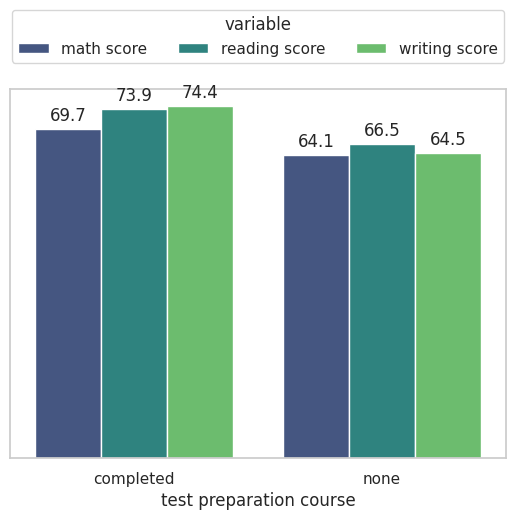

In [70]:
# Does test preparation improve performance?
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Group data
problem1 = df.groupby("test preparation course")[
    ["math score", "reading score", "writing score"]
].mean()

# 2. Set style
sns.set_style("whitegrid")

# 3. Create the plot and assign it to 'ax'
ax = sns.barplot(
    data=problem1.reset_index().melt(id_vars="test preparation course"),
    x="test preparation course",
    y="value",
    hue="variable",
    palette="viridis"
)

# 4. Hide the Y-axis completely
ax.get_yaxis().set_visible(False)

# 5. Position legend cleanly above the chart
ax.legend(
    title="variable",
    loc="lower center",
    bbox_to_anchor=(0.5, 1.05),
    # Places it just above the top center of the plot
    ncol=3
    # Arranges the items horizontally in a single row
)

# 6. Add value labels on top of the bars
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.1f",
        padding=3
    )

# 7. Display the plot
plt.show()

# Action Schools should encourage participation in preparation programs, especially for low-performing students.


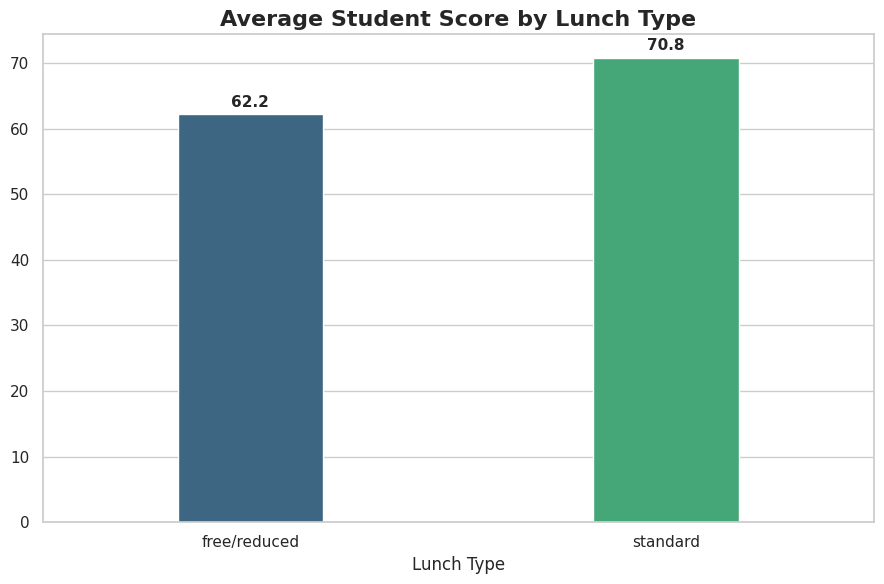

In [66]:
# Does lunch type influence performance?
problem2 = df.groupby("lunch")[
["math score", "reading score", "writing score"]
].mean()
problem2["average_score"] = problem2.mean(axis=1)
plt.figure(figsize=(9, 6))
ax = sns.barplot(
x=problem2.index,
y=problem2["average_score"],
palette="viridis",
width=0.35
)
# Values on bars
for container in ax.containers:
  ax.bar_label(
container,
fmt="%.1f",
fontsize=11,
fontweight="bold",
padding=3
)
plt.title(
"Average Student Score by Lunch Type",
fontsize=16,
fontweight="bold"
)
plt.xlabel("Lunch Type")

# Remove y-axis label
plt.ylabel("")
plt.tight_layout()
plt.show()

 # Problem Identified Achievement gaps linked to economic background.

 # Recommendation Provide tutoring and learning resources for economically disadvantaged students.

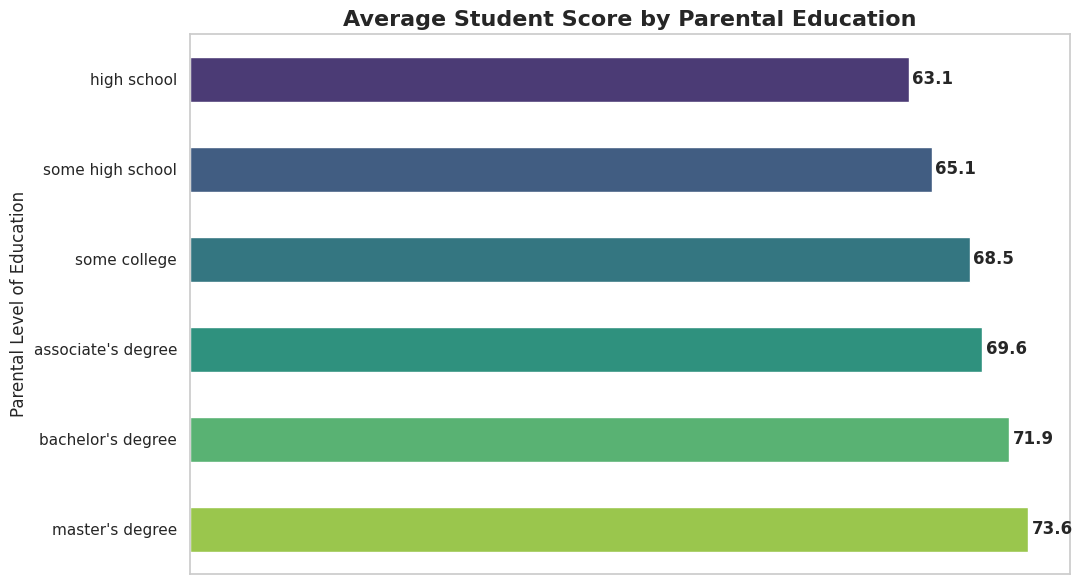

In [69]:
# Does parental education affect students' scores?
problem3 = df.groupby(
"parental level of education"
)["average_score"].mean().sort_values()
plt.figure(figsize=(11, 6))
ax = sns.barplot(
x=problem3.values,
y=problem3.index,
palette="viridis",
width=0.5
)
# Add scores at end of bars

for i, v in enumerate(problem3.values):
  plt.text(
v + 0.3, # Position slightly after bar
i, # Y position
f"{v:.1f}", # Score format
va="center",
fontweight="bold"
)
plt.title(
"Average Student Score by Parental Education",
fontsize=16,
fontweight="bold"
)
plt.xlabel("")
plt.ylabel("Parental Level of Education")
# Remove x-axis numbers
plt.xticks([])
plt.tight_layout()
plt.show()

# Action Offer additional academic support and mentoring to students whose parents have lower educational attainment.

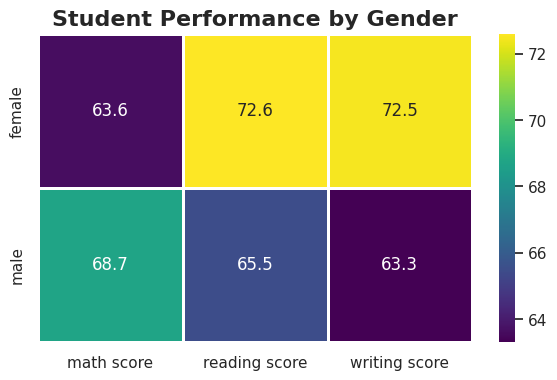

In [71]:
# Does lunch type influence performance?
plt.figure(figsize=(7, 4))
sns.heatmap(
gender_scores,
annot=True,
fmt=".1f",
cmap="viridis",
linewidths=1
)
plt.title(
"Student Performance by Gender",
fontsize=16,
fontweight="bold"
)
plt.ylabel("")
plt.xlabel("")
plt.show()

# Action Provide targeted support:

# Reading/Writing reinforcement for males.
# Math confidence programs for females.

In [31]:
# Top 10 Student
df.nlargest(10, 'average_score')

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,average_score
458,female,group E,bachelor's degree,standard,none,100,100,100,100.000000
916,male,group E,bachelor's degree,standard,completed,100,100,100,100.000000
962,female,group E,associate's degree,standard,none,100,100,100,100.000000
114,female,group E,bachelor's degree,standard,completed,99,100,100,99.666667
179,female,group D,some high school,standard,completed,97,100,100,99.000000
712,female,group D,some college,standard,none,98,100,99,99.000000
165,female,group C,bachelor's degree,standard,completed,96,100,100,98.666667
625,male,group D,some college,standard,completed,100,97,99,98.666667
149,male,group E,associate's degree,free/reduced,completed,100,100,93,97.666667
685,female,group E,master's degree,standard,completed,94,99,100,97.666667


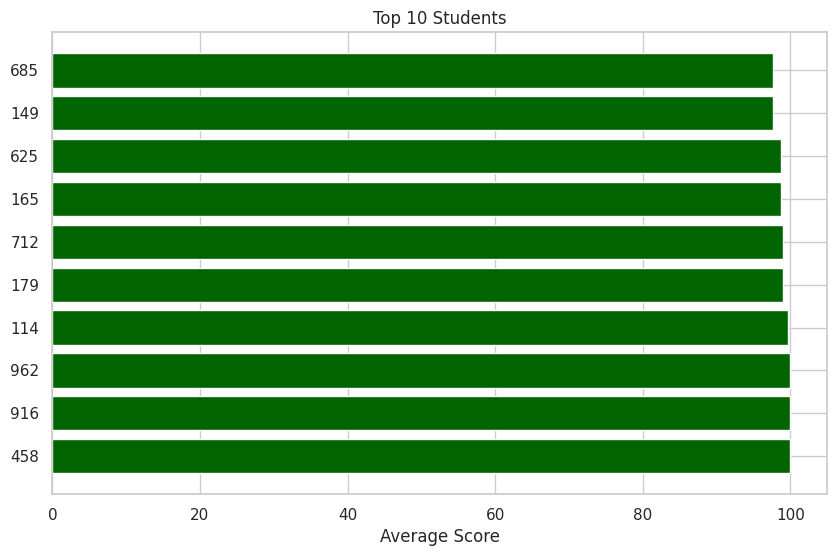

In [35]:
import matplotlib.pyplot as plt

top10 = df.nlargest(10, "average_score")
plt.figure(figsize=(10, 6))
plt.barh(
top10.index.astype(str),
top10["average_score"],
color="darkgreen"
)
plt.title("Top 10 Students")
plt.xlabel("Average Score")
plt.show()



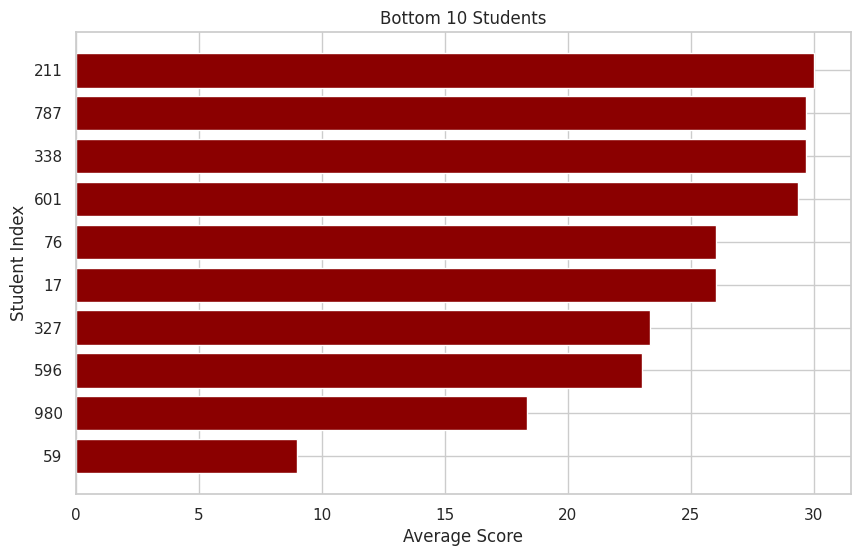

In [36]:
bottom10 = df.nsmallest(10, "average_score")
plt.figure(figsize=(10, 6))
plt.barh(
bottom10.index.astype(str),
bottom10["average_score"],
color="darkred"
)
plt.title("Bottom 10 Students")
plt.xlabel("Average Score")
plt.ylabel("Student Index")
plt.show()